In [ ]:
# Cell 1: Connect Google Drive & Setup
!pip install -q ultralytics kagglehub opencv-python matplotlib
# If YOLO-World asks for CLIP:
!pip install -q git+https://github.com/ultralytics/CLIP.git

from google.colab import drive
drive.mount('/content/drive')
print("Google Drive connected and environment ready!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 73.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.8 MB/s eta 0:00:00
Mounted at /content/drive
Google Drive connected and environment ready!


In [ ]:
# Cell 2: Build Dataset with YOLO-World Auto-Boxing
import kagglehub, random, hashlib, shutil
from pathlib import Path
from collections import defaultdict
from PIL import Image
from ultralytics import YOLOWorld

# Settings
SINGLE_CLASS = True      # Single "snake" class for high detection accuracy
MAX_PER_SPECIES = 60     # 60 images per species (~20,000 total images)
random.seed(42)

print("1. Downloading Kaggle Dataset...")
root = Path(kagglehub.dataset_download("khineaindrayhtun/snake-clef-data-classification"))
print(f"Dataset downloaded to: {root}")

IMG_EXTS = {".jpg", ".jpeg", ".png"}
by_species = defaultdict(list)
for d in root.rglob("*"):
    if d.is_dir():
        imgs = [f for f in d.iterdir() if f.suffix.lower() in IMG_EXTS]
        if imgs:
            by_species[d.name].extend(imgs)

species = sorted(by_species.keys())
print(f"Total Species Found: {len(species)} | Total Images: {sum(len(v) for v in by_species.values())}")

# Load YOLO-World (Zero-Shot Snake Localizer)
print("\n2. Loading YOLO-World to find snake bounding boxes...")
loc = YOLOWorld("yolov8x-worldv2.pt")
loc.set_classes(["snake"])

out = Path("snake_det")
cls_out = Path("snake_cls")
for p in (out, cls_out):
    if p.exists():
        shutil.rmtree(p)
    for s in ("train", "val", "test"):
        (p / s).mkdir(parents=True, exist_ok=True)
        if p == out:
            (out / "images" / s).mkdir(parents=True, exist_ok=True)
            (out / "labels" / s).mkdir(parents=True, exist_ok=True)

stats = defaultdict(int)
n = 0

print("3. Generating bounding boxes and species crops (please wait)...")
for sp_idx, sp in enumerate(species):
    # Remove duplicates
    seen, unique = set(), []
    for p in by_species[sp]:
        h = hashlib.md5(p.read_bytes()).hexdigest()
        if h not in seen:
            seen.add(h)
            unique.append(p)
    random.shuffle(unique)

    if MAX_PER_SPECIES:
        unique = unique[:int(MAX_PER_SPECIES * 1.3)]

    batch_paths = [str(u) for u in unique]
    if not batch_paths:
        continue

    labelled = []
    results = loc.predict(batch_paths, conf=0.15, stream=True, batch=16, half=True, verbose=False)
    for p, r in zip(unique, results):
        if len(labelled) >= (MAX_PER_SPECIES or 10**9):
            break
        if len(r.boxes) == 0:
            stats["no_box_skipped"] += 1
            continue

        b = r.boxes[int(r.boxes.conf.argmax())]
        xc, yc, w, h = b.xywhn[0].tolist()

        if w * h < 0.03:
            stats["tiny_box_skipped"] += 1
            continue

        labelled.append((p, xc, yc, w, h))

    # 70% Train, 20% Val, 10% Test
    n_tr = int(0.70 * len(labelled))
    n_va = int(0.20 * len(labelled))

    for i, (p, xc, yc, w, h) in enumerate(labelled):
        split = "train" if i < n_tr else "val" if i < (n_tr + n_va) else "test"
        name = f"sp{sp_idx}_{n}"
        n += 1

        # Save Detection image and label
        shutil.copy(p, out / "images" / split / f"{name}{p.suffix.lower()}")
        cid = 0
        (out / "labels" / split / f"{name}.txt").write_text(f"{cid} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")

        # Save cropped snake for Classifier
        try:
            im = Image.open(p).convert("RGB")
            W, H = im.size
            x1, y1 = max(0, (xc - w / 2 * 1.1) * W), max(0, (yc - h / 2 * 1.1) * H)
            x2, y2 = min(W, (xc + w / 2 * 1.1) * W), min(H, (yc + h / 2 * 1.1) * H)
            sp_folder = cls_out / split / sp
            sp_folder.mkdir(parents=True, exist_ok=True)
            im.crop((int(x1), int(y1), int(x2), int(y2))).save(sp_folder / f"{name}.jpg", quality=92)
        except Exception:
            pass

    if (sp_idx + 1) % 50 == 0 or (sp_idx + 1) == len(species):
        print(f"Processed {sp_idx + 1}/{len(species)} species...")

# Generate data.yaml
(out / "data.yaml").write_text(f"""path: {out.resolve()}
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: snake
""")

print("\n--- DATASET SUMMARY ---")
print("Skipped stats:", dict(stats))
for s in ("train", "val", "test"):
    count = len(list((out / "images" / s).glob("*")))
    print(f"  {s.upper()}: {count} images")
print("Dataset preparation complete!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
1. Downloading Kaggle Dataset...


100%|██████████| 3.14G/3.14G [02:27<00:00, 22.9MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/khineaindrayhtun/snake-clef-data-classification/versions/1
Total Species Found: 498 | Total Images: 105937

2. Loading YOLO-World to find snake bounding boxes...


100%|████████████████████████████████████████| 338M/338M [00:01<00:00, 281MiB/s]


3. Generating bounding boxes and species crops (please wait)...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is depre

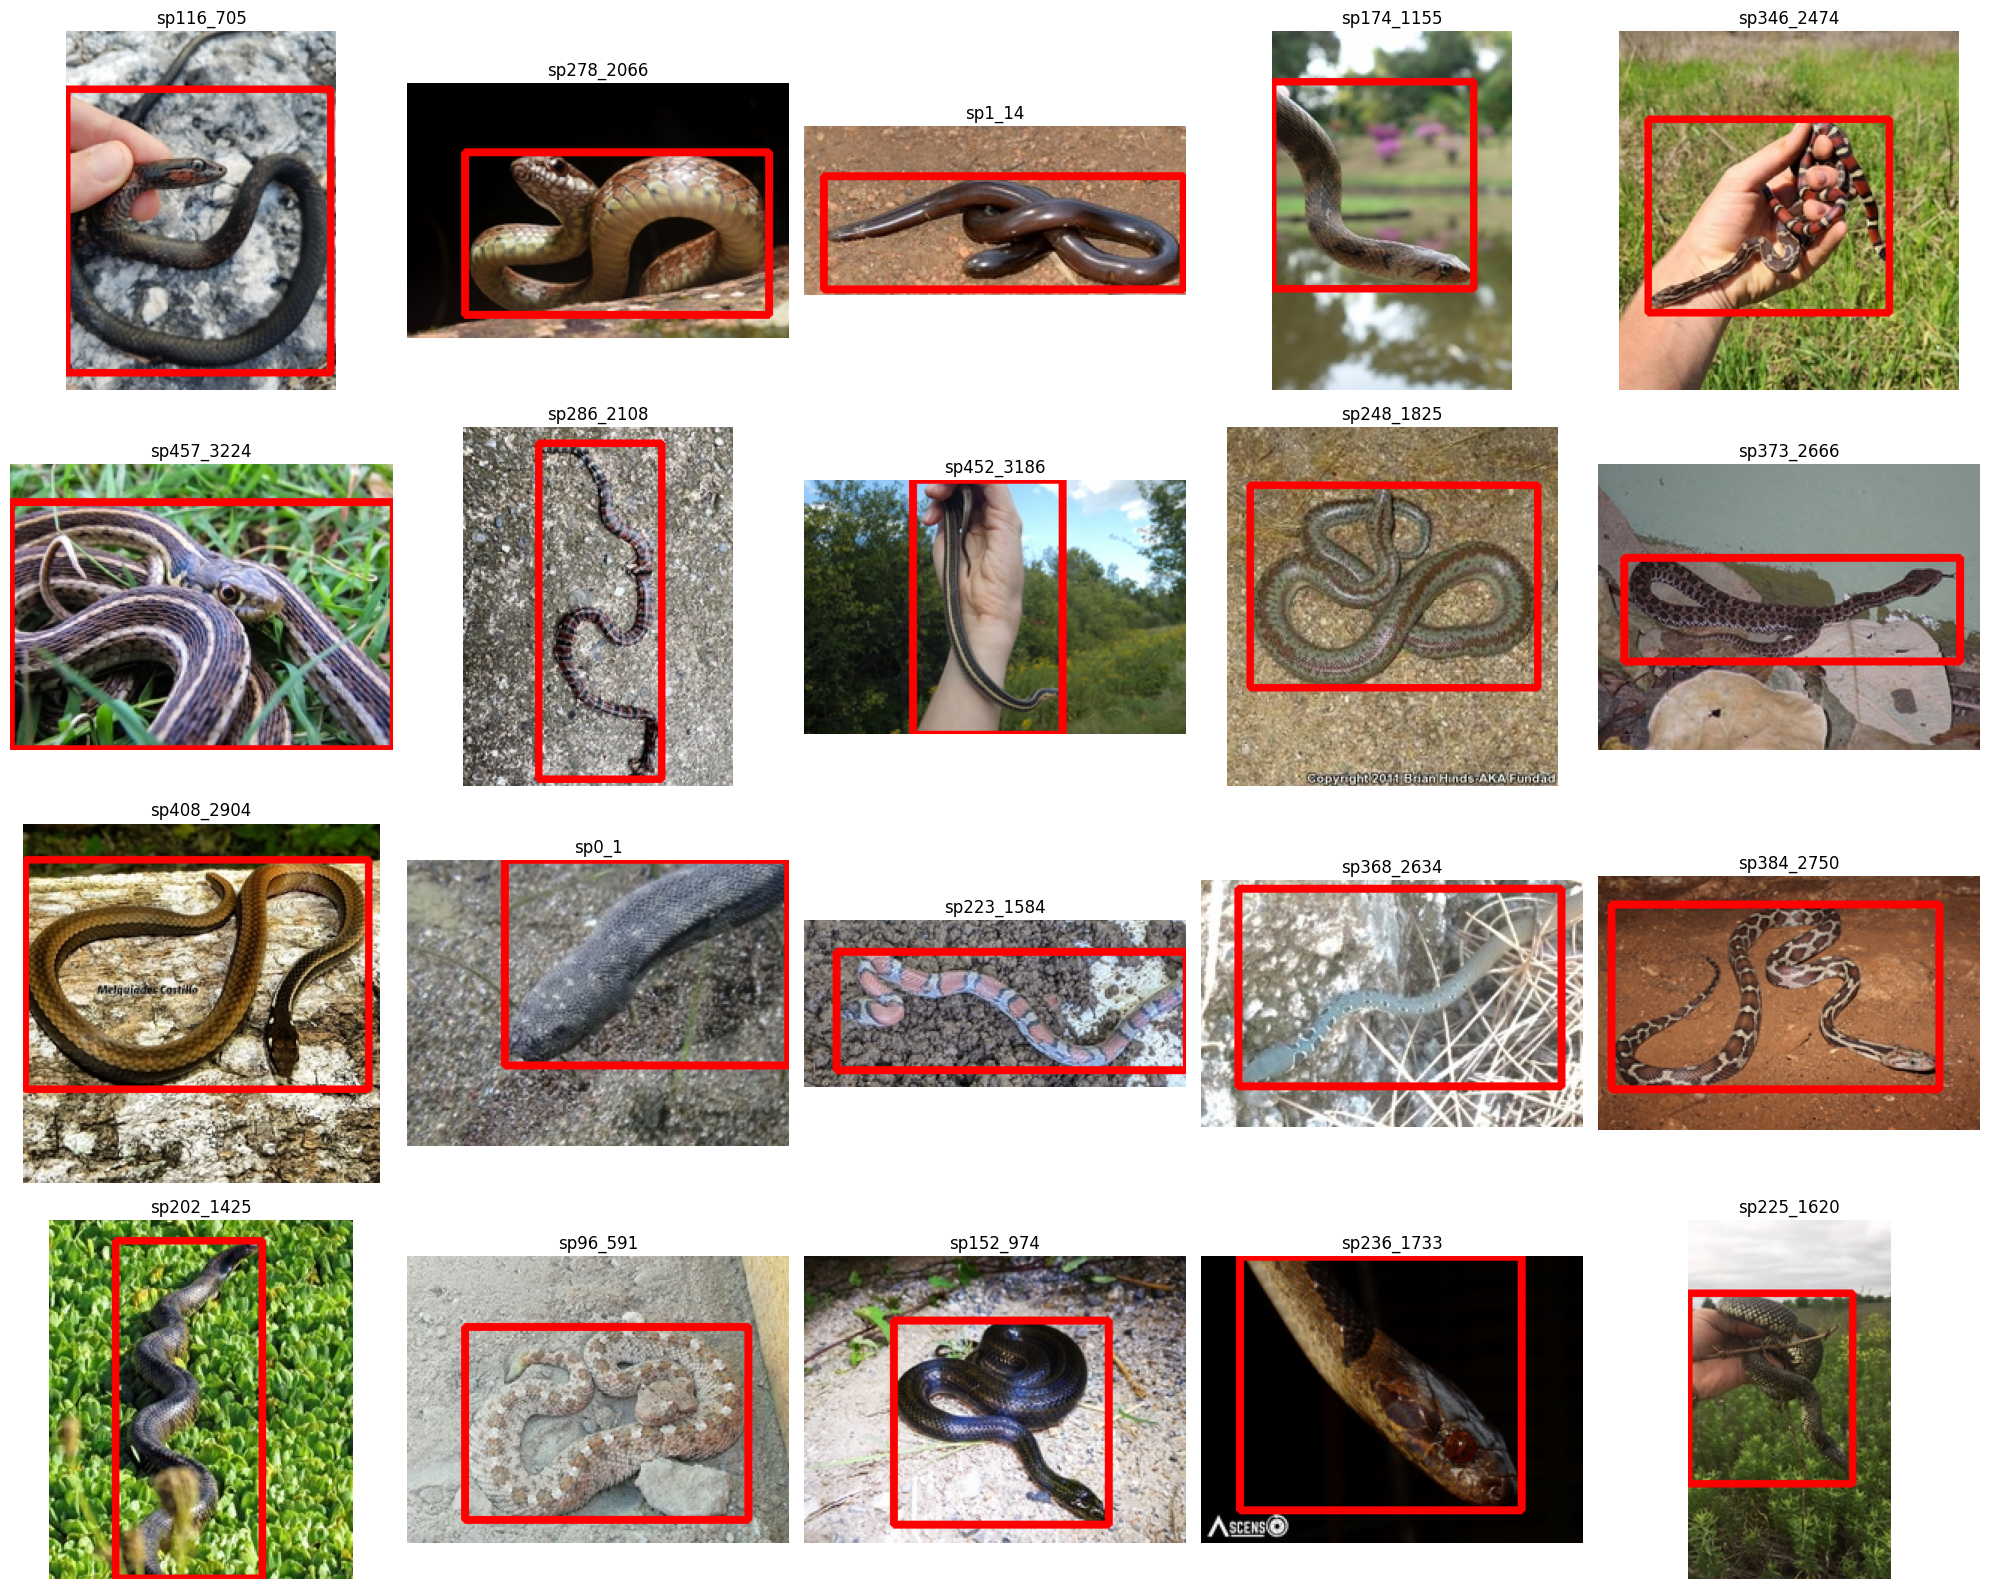

Inspect the 20 images above: Are the blue boxes tightly around the snakes?


In [ ]:
# Cell 3: Visual Inspection of 20 Random Boxes
import cv2, random
import matplotlib.pyplot as plt
from pathlib import Path

train_imgs = list(Path("snake_det/images/train").glob("*"))
sample_imgs = random.sample(train_imgs, min(20, len(train_imgs)))

fig, axes = plt.subplots(4, 5, figsize=(20, 16))
for ax, p in zip(axes.ravel(), sample_imgs):
    im = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    lbl_file = Path("snake_det/labels/train") / f"{p.stem}.txt"
    if lbl_file.exists():
        c, xc, yc, bw, bh = map(float, lbl_file.read_text().split())
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        cv2.rectangle(im, (x1, y1), (x2, y2), (255, 0, 0), max(3, w // 200))
    ax.imshow(im)
    ax.set_title(p.stem[:20])
    ax.axis("off")

plt.tight_layout()
plt.show()
print("Inspect the 20 images above: Are the blue boxes tightly around the snakes?")

In [ ]:
# Cell 4: Hook Powerful-IoU (PIoU) Loss (Wang et al. Eqs. 8-10)
import torch
import torch.nn.functional as F
from ultralytics.models.utils.loss import DETRLoss

piou_call_count = 0

def powerful_iou_loss(b1, b2, eps=1e-7):
    """
    Computes Powerful-IoU (PIoU) Loss (Wang et al. 2025, Eqs. 8-10):
      P = ((dw1 / W_gt) + (dw2 / W_gt) + (dh1 / H_gt) + (dh2 / H_gt)) / 4.0
      PIoU = IoU - (1 - exp(-P^2))
      L_PIoU = (1 - IoU) + (1 - exp(-P^2))
    """
    global piou_call_count
    piou_call_count += 1

    b1_x1, b1_x2 = b1[:, 0] - b1[:, 2] / 2, b1[:, 0] + b1[:, 2] / 2
    b1_y1, b1_y2 = b1[:, 1] - b1[:, 3] / 2, b1[:, 1] + b1[:, 3] / 2
    b2_x1, b2_x2 = b2[:, 0] - b2[:, 2] / 2, b2[:, 0] + b2[:, 2] / 2
    b2_y1, b2_y2 = b2[:, 1] - b2[:, 3] / 2, b2[:, 1] + b2[:, 3] / 2

    # Standard IoU
    inter_w = (torch.min(b1_x2, b2_x2) - torch.max(b1_x1, b2_x1)).clamp(min=0)
    inter_h = (torch.min(b1_y2, b2_y2) - torch.max(b1_y1, b2_y1)).clamp(min=0)
    inter_area = inter_w * inter_h
    union_area = (b1[:, 2] * b1[:, 3]) + (b2[:, 2] * b2[:, 3]) - inter_area + eps
    iou = inter_area / union_area

    # Dimensions
    w_gt = b2[:, 2].clamp(min=eps)
    h_gt = b2[:, 3].clamp(min=eps)

    # Edge distance penalties
    dw1 = torch.abs(b1_x1 - b2_x1)
    dw2 = torch.abs(b1_x2 - b2_x2)
    dh1 = torch.abs(b1_y1 - b2_y1)
    dh2 = torch.abs(b1_y2 - b2_y2)

    P = ((dw1 / w_gt) + (dw2 / w_gt) + (dh1 / h_gt) + (dh2 / h_gt)) / 4.0
    loss_piou = (1.0 - iou) + (1.0 - torch.exp(-(P ** 2)))
    return loss_piou

def patched_get_loss_bbox(self, pred_bboxes, gt_bboxes, postfix=""):
    name_bbox = f"loss_bbox{postfix}"
    name_piou = f"loss_giou{postfix}"
    loss = {}
    if len(gt_bboxes) == 0:
        loss[name_bbox] = pred_bboxes[..., :0].sum()
        loss[name_piou] = pred_bboxes[..., :0].sum()
        return loss

    loss[name_bbox] = self.loss_gain["bbox"] * F.l1_loss(pred_bboxes, gt_bboxes, reduction="sum") / len(gt_bboxes)
    piou_vals = powerful_iou_loss(pred_bboxes, gt_bboxes)
    loss[name_piou] = self.loss_gain["giou"] * (piou_vals.sum() / len(gt_bboxes))
    return {k: v.squeeze() for k, v in loss.items()}

DETRLoss._get_loss_bbox = patched_get_loss_bbox
print("Successfully hooked Powerful-IoU (PIoU) into DETRLoss engine!")

Successfully hooked Powerful-IoU (PIoU) into DETRLoss engine!


In [ ]:
# Cell 4b: 60-Second Smoke Test
from ultralytics import RTDETR

print("Running 1-epoch smoke test on 2% of data to verify PIoU patch...")
RTDETR('rtdetr-l.pt').train(
    data="snake_det/data.yaml",
    epochs=1,
    fraction=0.02,
    imgsz=640,
    batch=8,
    workers=2,
    name="smoke_test",
    exist_ok=True,
    project="/content/smoke"
)

print(f"\nSmoke Test Result: PIoU calls = {piou_call_count}")
assert piou_call_count > 0, "ERROR: PIoU was not called! Do not start long training."
print("VERIFICATION PASSED: PIoU is actively calculating loss! You are ready for full training.")

Running 1-epoch smoke test on 2% of data to verify PIoU patch...
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=snake_det/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.02, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=smoke_

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/1      9.31G     0.6235      18.98      1.312          3        640: 100% ━━━━━━━━━━━━ 6/6 1.6s/it 9.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 1.0it/s 30.2s
                   all        494        494     0.0563      0.103     0.0344     0.0164

1 epochs completed in 0.013 hours.
Optimizer stripped from /content/smoke/smoke_test/weights/last.pt, 66.2MB
Optimizer stripped from /content/smoke/smoke_test/weights/best.pt, 66.2MB

Validating /content/smoke/smoke_test/weights/best.pt...
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 1.0it/s 30.0s
                   all        494        494     0.0556     0.0972     0.0353     0.0167
Speed: 0.8ms preprocess, 28.7ms inferen

In [ ]:
# Cell 5: Train RT-DETR with PIoU to Google Drive
from ultralytics import RTDETR

model = RTDETR('rtdetr-l.pt')

# Train 20 epochs (stable, guaranteed to finish without timing out)
results = model.train(
    data="snake_det/data.yaml",
    epochs=20,
    patience=8,
    imgsz=640,
    batch=8,
    workers=2,
    optimizer="AdamW",     # Forces paper's optimizer
    lr0=0.0001,            # Paper's exact learning rate
    lrf=0.01,
    weight_decay=0.0001,   # Paper's exact weight decay
    cos_lr=True,
    warmup_epochs=2.0,
    seed=42,
    project="/content/drive/MyDrive/snake_runs",
    name="det_piou_run",
    save=True,
    plots=True
)

print("\nDetector training complete! Weights saved to Google Drive.")

Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=snake_det/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=det_piou_run-3, nbs=64, nms=None, opset=None, optimize=False, optimiz

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/20       7.6G     0.6098      1.669     0.7115         14        640: 100% ━━━━━━━━━━━━ 272/272 1.8it/s 2:32
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.5it/s 12.5s
                   all        494        494    0.00331      0.986     0.0259     0.0151

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       2/20      7.19G     0.4293      1.911     0.3403         10        640: 0% ──────────── 0/272  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/20      7.19G     0.2433      1.745     0.2642         12        640: 100% ━━━━━━━━━━━━ 272/272 1.8it/s 2:31
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.6it/s 12.0s
                   all        494        494     0.0456      0.308     0.0439     0.0317

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/20      7.19G     0.1931      1.705     0.2044         20        640: 0% ──────────── 0/272  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (31 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      19/20      7.19G     0.1144     0.2064     0.2525          5        640: 100% ━━━━━━━━━━━━ 272/272 1.8it/s 2:33
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.7it/s 11.6s
                   all        494        494       0.97      0.986      0.988       0.87

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      20/20      7.19G     0.1848     0.2428     0.3748          8        640: 0% ──────────── 0/272  0.6s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      20/20      7.19G     0.1096     0.2014     0.2398          5        640: 100% ━━━━━━━━━━━━ 272/272 1.8it/s 2:31
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.7it/s 11.5s
                   all        494        494      0.981      0.988      0.993      0.877

20 epochs completed in 0.944 hours.
Optimizer stripped from /content/drive/MyDrive/snake_runs/det_piou_run-3/weights/last.pt, 66.2MB
Optimizer stripped from /content/drive/MyDrive/snake_runs/det_piou_run-3/weights/best.pt, 66.2MB

Validating /content/drive/MyDrive/snake_runs/det_piou_run-3/weights/best.pt...
Ultralytics 8.4.181 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 31/31 2.3it/s 13.4s
                   all        494        494      0.98

In [1]:
# Cell 6: Train Species Classifier on the Cropped Snakes
from ultralytics import YOLO

clf = YOLO("yolov8m-cls.pt")

clf_results = clf.train(
    data="snake_cls",
    epochs=25,
    imgsz=224,
    batch=32,
    workers=2,
    optimizer="AdamW",
    lr0=0.0005,
    cos_lr=True,
    project="/content/drive/MyDrive/snake_runs",
    name="species_classifier_run"
)

# Evaluate on test split
clf_test = clf.val(data="snake_cls", split="test")
print(f"\n--- SPECIES IDENTIFIER ACCURACY ---")
print(f"Top-1 Accuracy: {clf_test.top1 * 100:.2f}%")
print(f"Top-5 Accuracy: {clf_test.top5 * 100:.2f}%")
print("-----------------------------------")

ModuleNotFoundError: No module named 'ultralytics'

In [ ]:
# Cell 7: Final Benchmark on Untouched 10% Test Split
from ultralytics import RTDETR

best_det = RTDETR("/content/drive/MyDrive/snake_runs/det_piou_run/weights/best.pt")

print("========================================================")
print("     FINAL DETECTOR EVALUATION ON HELD-OUT TEST SPLIT   ")
print("========================================================")

det_metrics = best_det.val(data="snake_det/data.yaml", split="test")

print("\n--- FINAL TEST SET METRICS ---")
print(f"Precision (P):       {det_metrics.box.mp * 100:.2f}%")
print(f"Recall (R):          {det_metrics.box.mr * 100:.2f}%")
print(f"mAP@0.5:             {det_metrics.box.map50 * 100:.2f}%")
print(f"mAP@0.5:0.95:        {det_metrics.box.map * 100:.2f}%")
print("========================================================")